In [1]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

# 오류 발생시
sklearn.set_config(display="text")

# CNN Animals10 데이터셋
- 웹에서 수집된 총 10가지 서로 다른 동물 카테고리의 이미지들로 구성되어 있습니다.
주로 이미지 분류 모델을 처음부터 학습시키거나 전이학습(Transfer Learning)을 실습하는 용도로 활용됩니다

[Animals10 데이터셋](https://www.kaggle.com/datasets/alessiocorrado99/animals10)

In [2]:
load_dotenv()
print(os.environ["KAGGLE_API_TOKEN"][:10])

KGAT_24595


In [3]:
# from kaggle.api.kaggle_api_extended import KaggleApi

# api = KaggleApi()
# api.authenticate()

# output_dir = r"C:\kdt_0900_hhj\ml\resource\dataset"
# os.makedirs(output_dir, exist_ok=True)
# api.dataset_download_files(r"alessiocorrado99/animals10", path=output_dir, unzip=True)

# print("다운로드 완료")

## ImageFolder
- 라벨링, 폴더를 가져와서 각 폴더의 레이블로 묶어주는 모듈

In [4]:
output_dir = r"C:\kdt_0900_hhj\ml\resource\dataset"

In [5]:
base_path = output_dir
folder_name = r"raw-img"
file_path = os.path.join(base_path, folder_name)

In [6]:
file_path

'C:\\kdt_0900_hhj\\ml\\resource\\dataset\\raw-img'

In [7]:
# 이미지를 가져올때 트랜스폼 해서 가져오게되는데 나누기전에 변환되어버리면 안되니(?) 트랜스폼 none 해야함
base_dataset = ImageFolder(root=file_path, transform=None)

In [8]:
# 데이터 나누기
total_size = len(base_dataset)
train_size = int(total_size * 0.8)
test_size = total_size - train_size

In [9]:
print(train_size, test_size)

20943 5236


In [10]:
# 변형하기 전이라 subset에 일단 담기 
train_subset, test_subset = random_split(base_dataset, [train_size, test_size])

In [11]:
print(len(train_subset), len(test_subset))

20943 5236


## tranform 정의

In [1]:
train_transform = transforms.Compose([
    transforms.Resize((64, 64)), # 크기를 변경
    transforms.Grayscale(1), # 흑백
    # transforms.RandomInvert(1),
    transforms.ToTensor(),
    transforms.Normalize(0.5, 0.5), # 정규화
])
test_transform = transforms.Compose([
    transforms.Resize((64, 64)), # 크기를 변경
    transforms.Grayscale(1), # 흑백
    # transforms.RandomInvert(1),
    transforms.ToTensor(),
    transforms.Normalize(0.5, 0.5), # 정규화
])

NameError: name 'transforms' is not defined

In [13]:
class DatasetWrapper(Dataset):
    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        x, y = self.dataset[idx]
        if self.transform:
            x = self.transform(x)
        return x, y

In [14]:
train_dataset = DatasetWrapper(train_subset, transform=train_transform)
test_dataset = DatasetWrapper(test_subset, transform=test_transform)

In [15]:
print(len(train_dataset), len(test_dataset))

20943 5236


In [16]:
class_dict = dict(enumerate(base_dataset.classes))
print(class_dict)

{0: 'cane', 1: 'cavallo', 2: 'elefante', 3: 'farfalla', 4: 'gallina', 5: 'gatto', 6: 'mucca', 7: 'pecora', 8: 'ragno', 9: 'scoiattolo'}


## 데이터 로더(DataLoader)

In [17]:
train_dataloader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [18]:
print(len(train_dataloader), len(test_dataloader))

328 82


In [19]:
imgs, labels = next(iter(train_dataloader))

In [20]:
print(imgs.size())

torch.Size([64, 1, 64, 64])


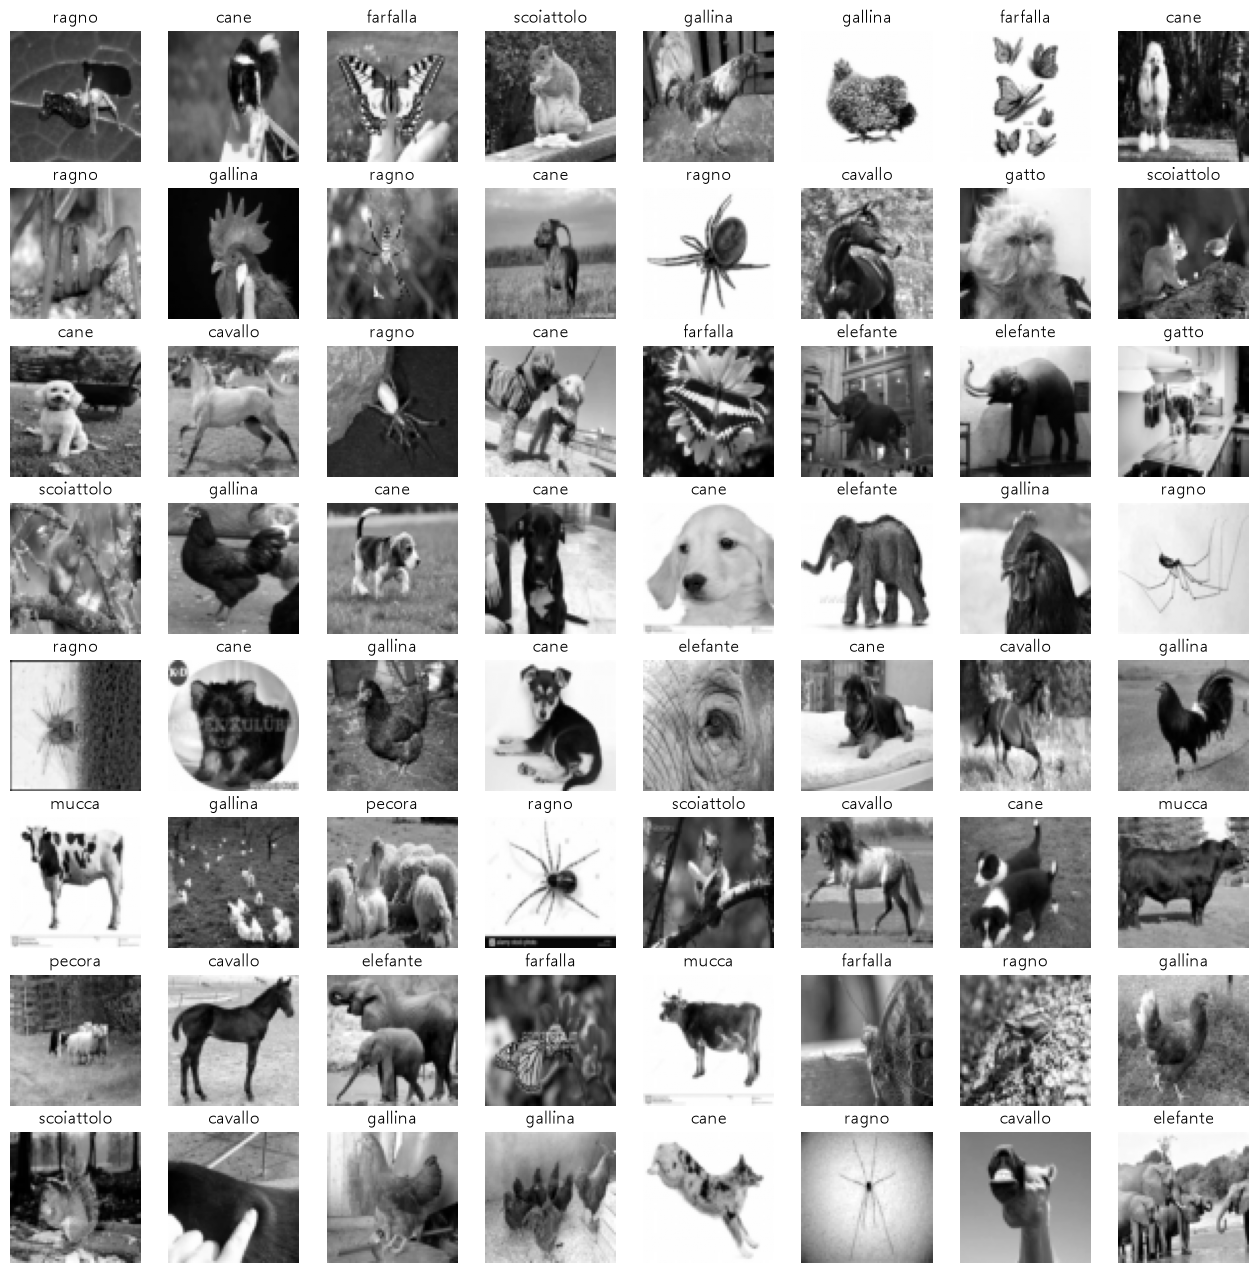

In [21]:
fig, axes = plt.subplots(8, 8, figsize=(16, 16))

for ax, img, label in zip(axes.flatten(), imgs, labels):
    ax.imshow(img.reshape(64, 64), cmap="gray")
    ax.set_title(class_dict[label.item()])
    ax.axis("off")

plt.show()

In [22]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: cuda


## CNN 모델 준비

In [23]:
class ConvNeuralNetwork(nn.Module):
    def __init__(self):
        super(ConvNeuralNetwork, self).__init__()
        self.flatten = nn.Flatten()
        self.classifier = nn.Sequential(
            nn.Conv2d(1, 28, kernel_size=3, padding="same"), #64, 64
            nn.ReLU(), # 활성화 함수(선형 -> 비선형)
            nn.Conv2d(28, 28, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2), # 32, 32
            nn.Dropout(0.25),
            
            nn.Conv2d(28, 56, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.Conv2d(56, 56, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2), # 16, 16
            nn.Dropout(0.25)
        )
        self.linear = nn.Linear(56 * 16 * 16, 10)
    
    def forward(self, x):
        x = self.classifier(x)
        x = self.flatten(x)
        x = self.linear(x)
        return x

In [24]:
model = ConvNeuralNetwork().to(device)

In [25]:
model

ConvNeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (classifier): Sequential(
    (0): Conv2d(1, 28, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): Conv2d(28, 28, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Dropout(p=0.25, inplace=False)
    (6): Conv2d(28, 56, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (7): ReLU()
    (8): Conv2d(56, 56, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (9): ReLU()
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (11): Dropout(p=0.25, inplace=False)
  )
  (linear): Linear(in_features=14336, out_features=10, bias=True)
)

In [26]:
criterion = nn.CrossEntropyLoss() # 예측 문제 손실함수와 , 분류 문제 손실함수는 다르다.
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [33]:
def train_one_epoch(model, dataloader, criterion, optimizer, device, log_step=20):
    model.train()
    total = 0
    running_loss = 0.0
    running_corrects = 0

    for i, (imgs, labels) in enumerate(dataloader, 1):
        imgs, labels = imgs.to(device), labels.to(device)

        # 초기화
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        batch_size = imgs.size(0)
        running_loss += loss.item() * batch_size
        _, preds = outputs.max(1)
        running_corrects += (preds == labels).sum().item()
        total += batch_size

        if log_step and i % log_step == 0:
            batch_acc = (preds == labels).float().mean().item()
            print(f"[Train] batch {i}/{len(dataloader)} | Loss: {loss:.4f} | Accuracy: {batch_acc:.2f}")

    return running_loss / total, running_corrects / total

In [35]:
def evaluate(model, dataloader, criterion, device):
    model.train()

    total = 0
    running_loss = 0.0
    running_corrects = 0

    with torch.no_grad():
        for i, (imgs, labels) in enumerate(dataloader, 1):
            imgs, labels = imgs.to(device), labels.to(device)
    
            # 초기화
            outputs = model(imgs)
            loss = criterion(outputs, labels)
    
            batch_size = imgs.size(0)
            running_loss += loss.item() * batch_size
            _, preds = outputs.max(1)
            running_corrects += (preds == labels).sum().item()
            total += batch_size
    

    return running_loss / total, running_corrects / total

In [37]:
epochs = 10

for i in range(epochs):
    # 학습
    train_loss, train_acc = train_one_epoch(
        model=model,
        
        dataloader=train_dataloader,
        criterion=criterion,
        optimizer=optimizer,
        device=device
    )

    # 평가
    test_loss, test_acc = evaluate(
        model=model,
        dataloader=test_dataloader,
        criterion=criterion,
        device=device
    )

    print(f"Epoch: {i}/{epochs}")
    print(f"[Train] Loss: {train_loss:.4f} | Accuracy: {train_acc}")
    print(f"[Test] Loss: {test_loss:.4f} | Accuracy: {test_acc}")

[Train] batch 20/328 | Loss: 0.3273 | Accuracy: 0.88
[Train] batch 40/328 | Loss: 0.4772 | Accuracy: 0.88
[Train] batch 60/328 | Loss: 0.5315 | Accuracy: 0.80
[Train] batch 80/328 | Loss: 0.5929 | Accuracy: 0.80
[Train] batch 100/328 | Loss: 0.7261 | Accuracy: 0.72
[Train] batch 120/328 | Loss: 0.5215 | Accuracy: 0.83
[Train] batch 140/328 | Loss: 0.4548 | Accuracy: 0.84
[Train] batch 160/328 | Loss: 0.5823 | Accuracy: 0.80
[Train] batch 180/328 | Loss: 0.5235 | Accuracy: 0.81
[Train] batch 200/328 | Loss: 0.8292 | Accuracy: 0.66
[Train] batch 220/328 | Loss: 0.6699 | Accuracy: 0.78
[Train] batch 240/328 | Loss: 0.4696 | Accuracy: 0.77
[Train] batch 260/328 | Loss: 0.4951 | Accuracy: 0.80
[Train] batch 280/328 | Loss: 0.6103 | Accuracy: 0.84
[Train] batch 300/328 | Loss: 0.6550 | Accuracy: 0.81
[Train] batch 320/328 | Loss: 0.6054 | Accuracy: 0.81
Epoch: 0/10
[Train] Loss: 0.5538 | Accuracy: 0.8051855035095259
[Test] Loss: 0.4527 | Accuracy: 0.8467745786181541
[Train] batch 20/328 | Lo

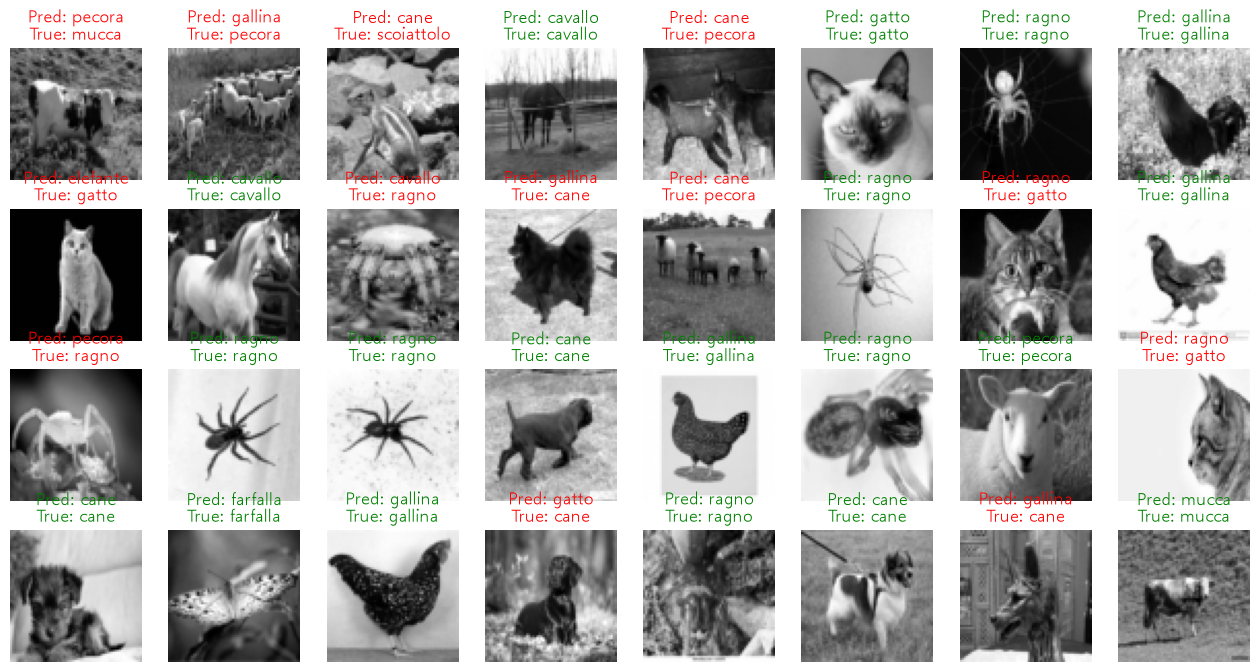

In [41]:
model.eval()

imgs, labels = next(iter(test_dataloader))
imgs_dev = imgs.to(device)

with torch.no_grad():
    outputs = model(imgs_dev)
    _, preds = outputs.max(1)

img_list_cpu = imgs.cpu()
y_pred_list_cpu = preds.cpu()
y_true_list_cpu = labels.cpu()

# 시각화
fig, axes = plt.subplots(4, 8, figsize=(16, 8))

for ax, img, y_pred, y_true in zip(axes.flatten(), img_list_cpu, y_pred_list_cpu, y_true_list_cpu):
    ax.imshow(img.squeeze(), cmap="gray")
    # ax.imshow(img.permute(1, 2, 0), cmap="gray")

    pred_label = class_dict[y_pred.item()]
    true_label = class_dict[y_true.item()]
    color = "green" if pred_label == true_label else "red"
    ax.axis("off")
    ax.set_title(f"Pred: {pred_label}\nTrue: {true_label}", color=color)

plt.show()

## 사진 들고오기

In [61]:
img_path = r"C:\kdt_0900_hhj\ml\resource\itsme.png"
img_path

'C:\\kdt_0900_hhj\\ml\\resource\\itsme.png'

In [43]:
from PIL import Image

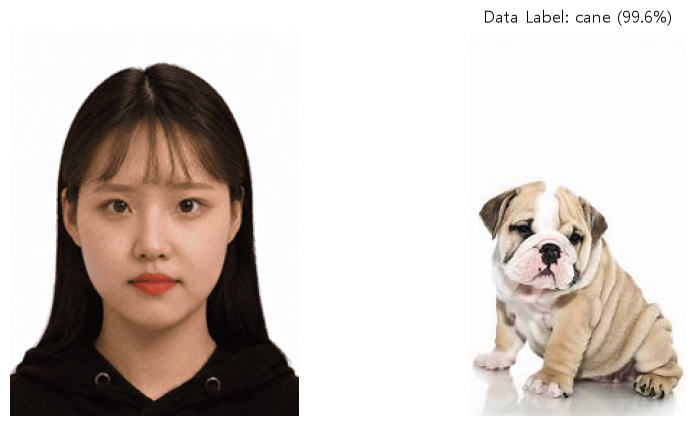

In [77]:
image = Image.open(img_path).convert("RGB")
input_tensor = test_transform(image)
input_tensor_dev = input_tensor.unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    outputs = model(input_tensor_dev)
    probs = F.softmax(outputs, dim=1)[0]

    pred_idx = torch.argmax(probs).item()
    pred_class = class_dict[pred_idx]
    confidence = probs[pred_idx].item() * 100

dataset_sample_img = None

for sample_img, sample_label in train_subset:
    if sample_label == pred_idx:
        dataset_sample_img = sample_img
        break

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
# 0 내이미지
axes[0].imshow(image)
axes[0].axis("off")

# 1: 닮은 이미지
axes[1].imshow(dataset_sample_img)
axes[1].set_title(f"Data Label: {pred_class} ({confidence:.1f}%)")
axes[1].axis("off")
    
plt.show()